# Анализ синтетических данных продаж интернет-магазина
В данном исследовании проводится предварительный анализ данных и визуализация с использованием трех библиотек:
1. **Matplotlib** — динамика выручки по месяцам.
2. **Seaborn** — распределение стоимости чека по товарным категориям.
3. **Plotly** — интерактивное соотношение цены, объема заказов и скидок.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_csv("data/sales_data.csv")
df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.to_period("M").dt.to_timestamp()

print("Размерность датасета:", df.shape)
print("\nПропущенные значения:\n", df.isna().sum())
print("\nОписательная статистика:")
display(df.describe())

Размерность датасета: (1500, 10)

Пропущенные значения:
 order_id            0
date                0
category            0
price               0
quantity            0
discount            0
total_cost          0
payment_method      0
customer_rating    78
month               0
dtype: int64

Описательная статистика:


,date,price,quantity,discount,total_cost,customer_rating,month
count,1500,1500.000000,1500.000000,1500.000000,1500.000000,1422.000000,1500
mean,2025-07-07 11:37:55.200000,50022.965440,1.419333,0.049433,67901.206100,4.124473,2025-06-22 23:52:19.200000
min,2025-01-01 00:00:00,2000.160000,1.000000,0.000000,2252.370000,1.000000,2025-01-01 00:00:00
25%,2025-04-05 18:00:00,15399.162500,1.000000,0.000000,17219.022500,4.000000,2025-04-01 00:00:00
50%,2025-07-13 00:00:00,39770.990000,1.000000,0.000000,45490.720000,4.000000,2025-07-01 00:00:00
75%,2025-10-07 00:00:00,72418.327500,2.000000,0.100000,89114.875000,5.000000,2025-10-01 00:00:00
max,2025-12-30 00:00:00,179384.060000,4.000000,0.200000,555785.520000,5.000000,2025-12-01 00:00:00
std,NaN,42032.565162,0.761498,0.060804,74331.662804,1.033216,NaN


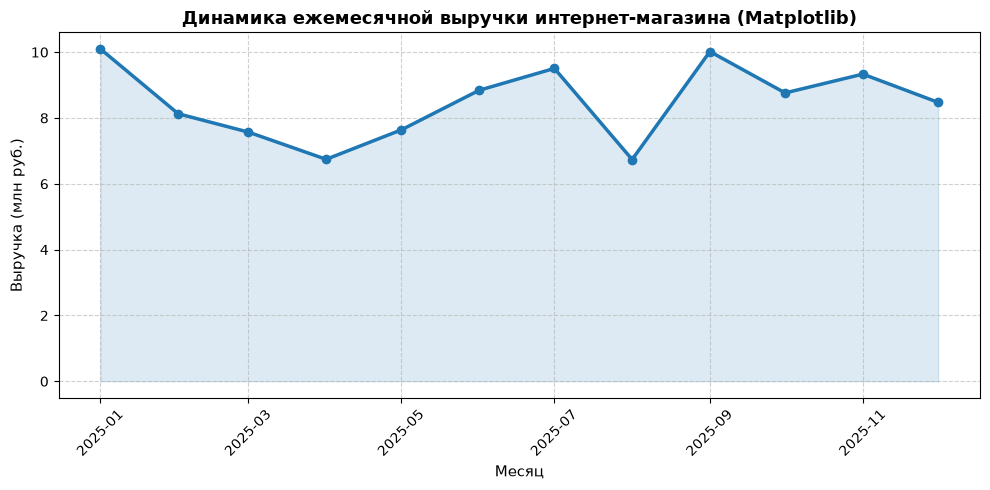

In [2]:
monthly_revenue = df.groupby("month")["total_cost"].sum().reset_index()

plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue["month"], monthly_revenue["total_cost"] / 1e6, marker="o", color="#1f77b4", linewidth=2.5)
plt.fill_between(monthly_revenue["month"], monthly_revenue["total_cost"] / 1e6, color="#1f77b4", alpha=0.15)

plt.title("Динамика ежемесячной выручки интернет-магазина (Matplotlib)", fontsize=13, fontweight="bold")
plt.xlabel("Месяц", fontsize=11)
plt.ylabel("Выручка (млн руб.)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

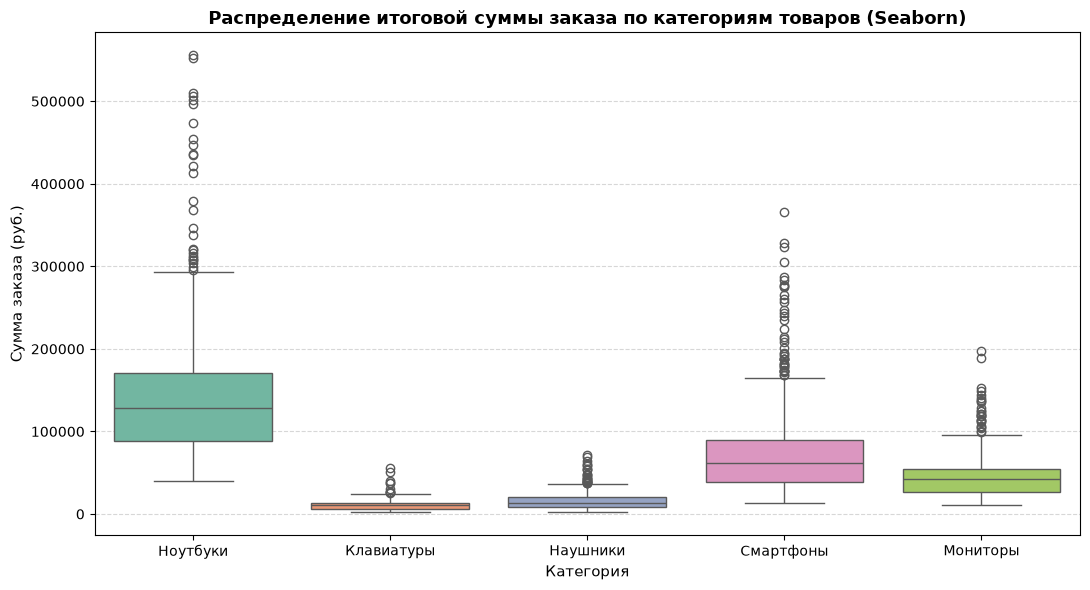

In [3]:
plt.figure(figsize=(11, 6))
sns.boxplot(
    data=df, 
    x="category", 
    y="total_cost", 
    hue="category", 
    palette="Set2", 
    legend=False
)

plt.title("Распределение итоговой суммы заказа по категориям товаров (Seaborn)", fontsize=13, fontweight="bold")
plt.xlabel("Категория", fontsize=11)
plt.ylabel("Сумма заказа (руб.)", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [4]:
cat_payment = df.groupby(["category", "payment_method"])["total_cost"].sum().reset_index()

fig = px.bar(
    cat_payment,
    x="category",
    y="total_cost",
    color="payment_method",
    title="Интерактивная структура выручки по категориям и способам оплаты (Plotly)",
    labels={"total_cost": "Выручка (руб.)", "category": "Категория", "payment_method": "Способ оплаты"},
    barmode="group",
    template="plotly_white"
)

fig.update_layout(xaxis_title="Категория товаров", yaxis_title="Суммарная выручка (руб.)")
fig.show()